<a href="https://colab.research.google.com/github/ldbanks/github-tutorial-mm-tools/blob/master/Copy_of_AlphaFold2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ColabFold: AlphaFold2 w/ MMseqs2

<img src="https://raw.githubusercontent.com/sokrypton/ColabFold/main/.github/ColabFold_Marv_Logo_Small.png" height="256" align="right" style="height:256px">

Easy to use AlphaFold2 protein structure [(Jumper et al. 2021)](https://www.nature.com/articles/s41586-021-03819-2) and complex [(Evans et al. 2021)](https://www.biorxiv.org/content/10.1101/2021.10.04.463034v1) prediction using multiple sequence alignments generated through MMseqs2. For details, refer to our manuscript:

[Mirdita M, Schütze K, Moriwaki Y, Heo L, Ovchinnikov S, Steinegger M. ColabFold - Making protein folding accessible to all.
*bioRxiv*, 2021](https://www.biorxiv.org/content/10.1101/2021.08.15.456425v2)

- This notebook provides basic functionality for **protein structure (Alphafold2)** and **complex prediction (Alphafold2-multimer)**. Advanced features such as recycles, sampling, ... ->[advanced notebook](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/beta/AlphaFold2_advanced.ipynb).
- This notebook replaces the homology detection and MSA pairing of AlphaFold2 with MMseqs2. For a comparision against the [Deepmind Colab](https://colab.research.google.com/github/deepmind/alphafold/blob/main/notebooks/AlphaFold.ipynb) and the full [AlphaFold2](https://github.com/deepmind/alphafold) system read our [preprint](https://www.biorxiv.org/content/10.1101/2021.08.15.456425v1).

Old versions: [v1.0-alpha](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.0-alpha/AlphaFold2.ipynb), [v1.1-permultimer](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.1-premultimer/AlphaFold2.ipynb)

For more details, see **<a href="#Instructions">bottom</a>** of the notebook and checkout the **[ColabFold GitHub](https://github.com/sokrypton/ColabFold)**.

In [ ]:
#@title Input protein sequence, then hit `Runtime` -> `Run all`
from google.colab import files
import os.path
import re
import hashlib

def add_hash(x,y):
  return x+"_"+hashlib.sha1(y.encode()).hexdigest()[:5]

query_sequence = 'MVLSEGEWQLVLHVWAKVEADVAGHGQDILIRLFKSHPETLEKFDRFKHLKTEAEMKASEDLKKHG' #@param {type:"string"}
#@markdown  - Use `:` to specify inter-protein chainbreaks for **modeling complexes** (supports homo- and hetro-oligomers). For example **PI...SK:PI...SK** for a mono-dimer

# remove whitespaces
query_sequence = "".join(query_sequence.split())

jobname = 'test' #@param {type:"string"}
# remove whitespaces
jobname = "".join(jobname.split())
jobname = re.sub(r'\W+', '', jobname)
jobname = add_hash(jobname, query_sequence)


with open(f"{jobname}.csv", "w") as text_file:
    text_file.write(f"id,sequence\n{jobname},{query_sequence}")

queries_path=f"{jobname}.csv"

# number of models to use
#@markdown ---
#@markdown ### Advanced settings
msa_mode = "MMseqs2 (UniRef+Environmental)" #@param ["MMseqs2 (UniRef+Environmental)", "MMseqs2 (UniRef only)","single_sequence","custom"]
num_models = 5 #@param [1,2,3,4,5] {type:"raw"}
num_recycles = 3 #@param [1,3,6,12,24,48] {type:"raw"}
use_msa = True if msa_mode.startswith("MMseqs2") else False
use_env = True if msa_mode == "MMseqs2 (UniRef+Environmental)" else False
use_amber = False #@param {type:"boolean"}
use_templates = False #@param {type:"boolean"}

#@markdown ---
#@markdown ### Experimental options
save_to_google_drive = False #@param {type:"boolean"}
#@markdown ---
#@markdown Don't forget to hit `Runtime` -> `Run all` after updating the form.

with open(f"{jobname}.log", "w") as text_file:
    text_file.write("num_models=%s\n" % num_models)
    text_file.write("use_amber=%s\n" % use_amber)
    text_file.write("use_msa=%s\n" % use_msa)
    text_file.write("msa_mode=%s\n" % msa_mode)
    text_file.write("use_templates=%s\n" % use_templates)

# decide which a3m to use
if use_msa:
  a3m_file = f"{jobname}.a3m"
elif msa_mode == "custom":
  a3m_file = f"{jobname}.custom.a3m"
  if not os.path.isfile(a3m_file):
    custom_msa_dict = files.upload()
    custom_msa = list(custom_msa_dict.keys())[0]
    header = 0
    import fileinput
    for line in fileinput.FileInput(custom_msa,inplace=1):
      if line.startswith(">"):
         header = header + 1
      if line.startswith("#"):
        continue
      if not line.rstrip():
        continue
      if line.startswith(">") == False and header == 1:
         query_sequence = line.rstrip()
      print(line, end='')

    os.rename(custom_msa, a3m_file)
    queries_path=a3m_file
    print(f"moving {custom_msa} to {a3m_file}")
else:
  a3m_file = f"{jobname}.single_sequence.a3m"
  with open(a3m_file, "w") as text_file:
    text_file.write(">1\n%s" % query_sequence)

if save_to_google_drive:
  from pydrive.drive import GoogleDrive
  from pydrive.auth import GoogleAuth
  from google.colab import auth
  from oauth2client.client import GoogleCredentials
  auth.authenticate_user()
  gauth = GoogleAuth()
  gauth.credentials = GoogleCredentials.get_application_default()
  drive = GoogleDrive(gauth)
  print("You are logged into Google Drive and are good to go!")

In [ ]:
#@title Install dependencies
%%bash -s $use_amber $use_msa $use_templates

set -e

USE_AMBER=$1
USE_MSA=$2
USE_TEMPLATES=$3

# Force dependency installation directly to bypass any existing flag issues
pip install -q biopython dm-haiku ml-collections py3Dmol
pip uninstall -y -q colabfold
pip install -q "colabfold[alphafold]"
touch COLABFOLD_READY

# download libraries for interfacing with MMseqs2 API
if [ ${USE_MSA} == "True" ] || [ ${USE_TEMPLATES} == "True" ]; then
  if [ ! -f MMSEQ2_READY ]; then
    apt-get -qq -y update 2>&1 1>/dev/null
    apt-get -qq -y install jq curl zlib1g gawk 2>&1 1>/dev/null
    touch MMSEQ2_READY
  fi
fi
# setup conda
if [ ${USE_AMBER} == "True" ] || [ ${USE_TEMPLATES} == "True" ]; then
  if [ ! -f CONDA_READY ]; then
    wget -qnc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
    bash Miniconda3-latest-Linux-x86_64.sh -bfp /usr/local 2>&1 1>/dev/null
    rm Miniconda3-latest-Linux-x86_64.sh
    touch CONDA_READY
  fi
fi
# setup template search
if [ ${USE_TEMPLATES} == "True" ] && [ ! -f HH_READY ]; then
  conda install -y -q -c conda-forge -c bioconda kalign3=3.2.2 hhsuite=3.3.0 python=3.7 2>&1 1>/dev/null
  touch HH_READY
fi
# setup openmm for amber refinement
if [ ${USE_AMBER} == "True" ] && [ ! -f AMBER_READY ]; then
  conda install -y -q -c conda-forge openmm=7.5.1 python=3.7 pdbfixer 2>&1 1>/dev/null
  wget -qnc https://raw.githubusercontent.com/deepmind/alphafold/main/docker/openmm.patch
  (cd /usr/local/lib/python3.7/site-packages; patch -s -p0 < /content/openmm.patch)
  wget -qnc https://git.scicore.unibas.ch/schwede/openstructure/-/raw/7102c63615b64735c4941278d92b554ec94415f8/modules/mol/alg/src/stereo_chemical_props.txt
  touch AMBER_READY
fi

In [ ]:
%%bash
# Remove existing setup indicators so that the installation can re-run
rm -f COLABFOLD_READY MMSEQ2_READY CONDA_READY HH_READY AMBER_READY
echo "Cleanup completed. You can now re-run the 'Install dependencies' cell above."

Cleanup completed. You can now re-run the 'Install dependencies' cell above.


In [ ]:
#@title Run Prediction

import sys

# Ensure the colabfold module is loaded correctly after the clean installation
from colabfold.download import download_alphafold_params, default_data_dir
from colabfold.utils import setup_logging
from colabfold.batch import get_queries, run

from pathlib import Path

# For some reason we need that to get pdbfixer to import
if use_amber and '/usr/local/lib/python3.7/site-packages/' not in sys.path:
    sys.path.insert(0, '/usr/local/lib/python3.7/site-packages/')

result_dir="."
setup_logging(Path(".").joinpath("log.txt"))
queries, is_complex = get_queries(queries_path)

# Map the is_complex boolean to the appropriate model type string expected by colabfold
model_type = "alphafold2_multimer_v3" if is_complex else "alphafold2_ptm"
download_alphafold_params(model_type, Path("."))

run(
    queries=queries,
    result_dir=result_dir,
    use_templates=use_templates,
    use_amber=use_amber,
    msa_mode=msa_mode,
    num_models=num_models,
    num_recycles=num_recycles,
    model_order=[1, 2, 3, 4, 5],
    is_complex=is_complex,
    data_dir=Path("."),
    keep_existing_results=False,
    recompile_padding=1.0,
    rank_mode="auto",
    pair_mode="unpaired+paired",
    stop_at_score=float(100),
)

2026-10-29 17:11:18,693 Running on GPU
2026-10-29 17:11:19,247 Found 5 citations for tools or databases
2026-10-29 17:11:19,247 Query 1/1: test_451ef (length 66)
2026-10-29 17:11:19,252 No user agent specified. Please set a user agent (e.g., 'toolname/version contact@email') to help us debug in case of problems. This warning will become an error in the future.


PENDING:   0%|          | 0/150 [elapsed: 00:00 remaining: ?]

2026-10-29 17:11:19,541 Sleeping for 10s. Reason: PENDING


RUNNING:   7%|▋         | 10/150 [elapsed: 00:10 remaining: 02:27]

2026-10-29 17:11:29,818 Sleeping for 7s. Reason: RUNNING


RUNNING:  11%|█▏        | 17/150 [elapsed: 00:17 remaining: 02:19]

2026-10-29 17:11:37,081 Sleeping for 7s. Reason: RUNNING


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:25 remaining: 00:00]


2026-10-29 17:11:45,745 Setting max_seq=512, max_extra_seq=3057
2026-10-29 17:12:24,369 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=92.4 pTM=0.702
2026-10-29 17:12:27,929 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=93.1 pTM=0.708 tol=0.491
2026-10-29 17:12:31,507 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=93.9 pTM=0.719 tol=0.423
2026-10-29 17:12:35,094 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=94.3 pTM=0.725 tol=0.141
2026-10-29 17:12:35,095 alphafold2_ptm_model_1_seed_000 took 40.6s (3 recycles)
2026-10-29 17:12:38,705 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=91.4 pTM=0.688
2026-10-29 17:12:42,318 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=93.8 pTM=0.719 tol=0.356
2026-10-29 17:12:45,945 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=94.2 pTM=0.724 tol=0.303
2026-10-29 17:12:49,579 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=95.1 pTM=0.737 tol=0.184
2026-10-29 17:12:49,580 alphafold2_ptm_model_2_seed_000 took 14.5s (3 recycles)
2026-10-29 17:12:53,

{'rank': [['rank_001_alphafold2_ptm_model_5_seed_000',
   'rank_002_alphafold2_ptm_model_2_seed_000',
   'rank_003_alphafold2_ptm_model_1_seed_000',
   'rank_004_alphafold2_ptm_model_4_seed_000',
   'rank_005_alphafold2_ptm_model_3_seed_000']],
 'metric': [[{'mean_plddt': 95.5,
    'ptm': 0.7509765625,
    'print_line': ' pLDDT=95.5 pTM=0.751'},
   {'mean_plddt': 95.0625,
    'ptm': 0.73681640625,
    'print_line': ' pLDDT=95.1 pTM=0.737'},
   {'mean_plddt': 94.3125,
    'ptm': 0.724609375,
    'print_line': ' pLDDT=94.3 pTM=0.725'},
   {'mean_plddt': 94.25,
    'ptm': 0.7216796875,
    'print_line': ' pLDDT=94.2 pTM=0.722'},
   {'mean_plddt': 90.125,
    'ptm': 0.65283203125,
    'print_line': ' pLDDT=90.1 pTM=0.653'}]]}

In [ ]:
#@title Display 3D structure
import glob
import py3Dmol

#@markdown Choose a rank to display:
rank_num = 1 #@param [1, 2, 3, 4, 5] {type:"raw"}
color = "lDDT" #@param ["lDDT", "rainbow"]
show_sidechains = False #@param {type:"boolean"}
show_mainchains = False #@param {type:"boolean"}

# Search dynamically for the unrelaxed PDB file matching the requested rank
pdb_patterns = [
    f"{jobname}_unrelaxed_rank_{rank_num:03d}*.pdb",
    f"{jobname}_relaxed_rank_{rank_num:03d}*.pdb",
    f"{jobname}_unrelaxed_rank_{rank_num}*.pdb",
    f"{jobname}_relaxed_rank_{rank_num}*.pdb"
]

pdb_files = []
for pat in pdb_patterns:
    pdb_files.extend(glob.glob(pat))

if not pdb_files:
    # Fallback to general rank match
    pdb_files = glob.glob(f"*{rank_num}*.pdb")

if pdb_files:
    pdb_file = pdb_files[0]
    print(f"Displaying {pdb_file}")

    # Render with py3Dmol
    view = py3Dmol.view(js='https://3dmol.org/build/3Dmol-min.js')
    with open(pdb_file, 'r') as f:
        view.addModel(f.read(), 'pdb')

    if color == "lDDT":
        view.setStyle({'cartoon': {'colorscheme': {'prop': 'b', 'gradient': 'roygb', 'min': 50, 'max': 90}}})
    else:
        view.setStyle({'cartoon': {'color': 'spectrum'}})

    if show_sidechains:
        view.addStyle({'and': [{'resn': ["GLY","PRO"], 'invert': True}, {'sidechain': True}]}, {'stick': {'colorscheme': 'Carbon', 'radius': 0.15}})
    if show_mainchains:
        view.addStyle({'cartoon': {'color': 'spectrum'}}, {'stick': {'colorscheme': 'Carbon', 'radius': 0.15}})

    view.zoomTo()
    view.show()
else:
    print(f"Could not find a PDB file matching rank {rank_num}. Please make sure predictions completed successfully.")

Displaying test_451ef_unrelaxed_rank_001_alphafold2_ptm_model_5_seed_000.pdb


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Displaying PAE plot: test_451ef_pae.png


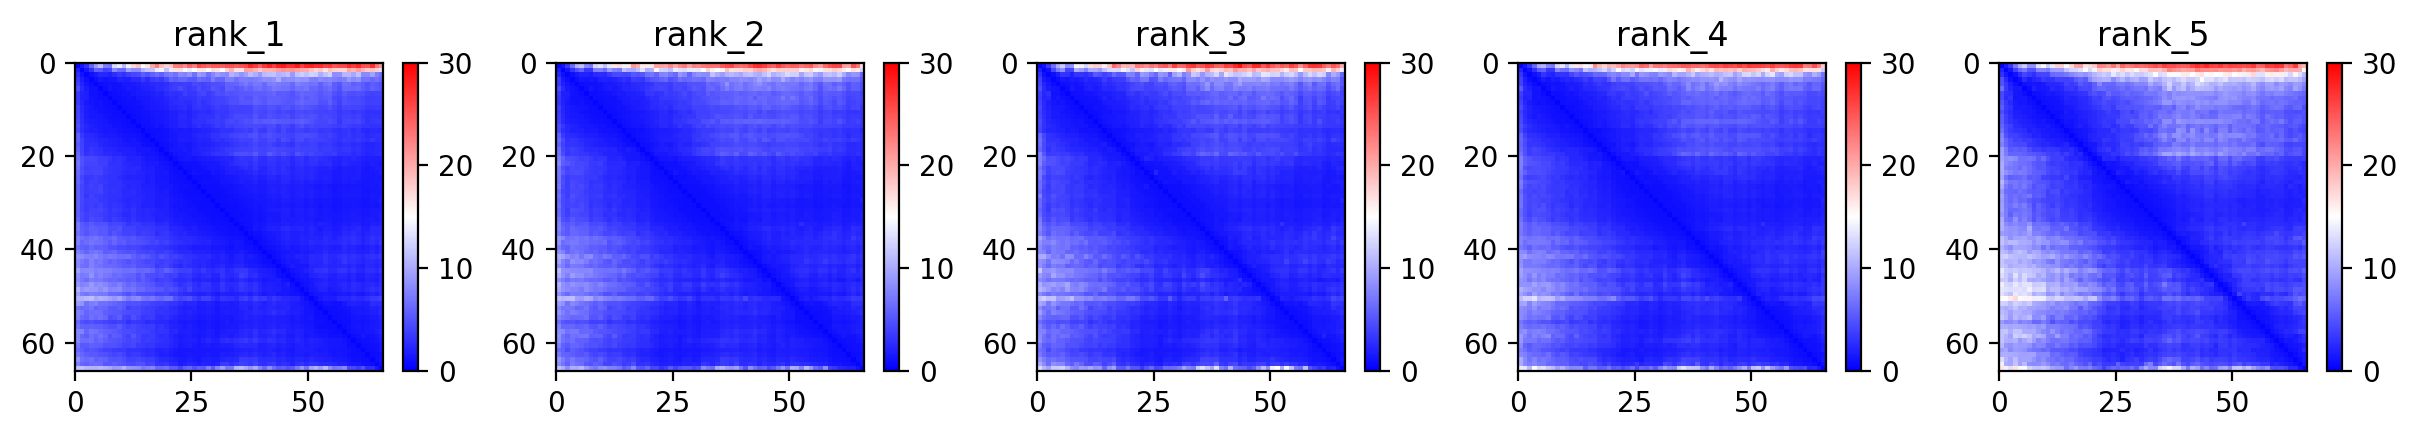

In [ ]:
#@title Display Predicted Aligned Error (PAE)
import os
from IPython.display import Image, display

pae_image_path = f"{jobname}_pae.png"

if os.path.exists(pae_image_path):
    print(f"Displaying PAE plot: {pae_image_path}")
    display(Image(pae_image_path))
else:
    print(f"Could not find PAE plot at {pae_image_path}. Please make sure prediction completed successfully.")

In [ ]:
#@title Package and download results
#@markdown If you are having issues downloading the result archive, try disabling your adblocker and run this cell again. If that fails click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select "Download" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).

if msa_mode == "custom":
  print("Don't forget to cite your custom MSA generation method.")
if msa_mode != "custom":
  !cat $jobname"_env/"*".a3m" > $jobname".a3m"

# Updated to match current output filenames for PDBs, PAE plots, and pLDDT plots
!zip -FSr $jobname".result.zip" $jobname".log" $a3m_file $jobname*"rank_"*".pdb" $jobname*"_coverage.png" $jobname*"_plddt.png" "cite.bibtex" $jobname*"_pae.png" $jobname*"_predicted_aligned_error_v1.json"
files.download(f"{jobname}.result.zip")

if save_to_google_drive == True and drive:
  uploaded = drive.CreateFile({'title': f"{jobname}.result.zip"})
  uploaded.SetContentFile(f"{jobname}.result.zip")
  uploaded.Upload()
  print(f"Uploaded {jobname}.result.zip to Google Drive with ID {uploaded.get('id')}")

updating: test_451ef.a3m (deflated 68%)
  adding: test_451ef_unrelaxed_rank_001_alphafold2_ptm_model_5_seed_000.pdb (deflated 78%)
  adding: test_451ef_unrelaxed_rank_002_alphafold2_ptm_model_2_seed_000.pdb (deflated 78%)
  adding: test_451ef_unrelaxed_rank_003_alphafold2_ptm_model_1_seed_000.pdb (deflated 78%)
  adding: test_451ef_unrelaxed_rank_004_alphafold2_ptm_model_4_seed_000.pdb (deflated 78%)
  adding: test_451ef_unrelaxed_rank_005_alphafold2_ptm_model_3_seed_000.pdb (deflated 78%)
  adding: test_451ef_coverage.png (deflated 9%)
  adding: test_451ef_plddt.png (deflated 11%)
  adding: test_451ef_pae.png (deflated 12%)
  adding: test_451ef_predicted_aligned_error_v1.json (deflated 70%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Instructions <a name="Instructions"></a>
**Quick start**
1. Paste your protein sequence(s) in the input field.
2. Press "Runtime" -> "Run all".
3. The pipeline consists of 5 steps. The currently running steps is indicated by a circle with a stop sign next to it.

**Result zip file contents**

1. PDB formatted structures sorted by avg. pIDDT and complexes are sorted by pTMscore. (unrelaxed and relaxed if `use_amber` is enabled).
2. Plots of the model quality.
3. Plots of the MSA coverage.
4. Parameter log file.
5. A3M formatted input MSA.
6. BibTeX file with citations for all used tools and databases.

At the end of the job a download modal box will pop up with a `jobname.result.zip` file. Additionally, if the `save_to_google_drive` option was selected, the `jobname.result.zip` will be uploaded to your Google Drive.

**MSA generation for complexes**

For the complex prediction we use unpaired and paired MSAs. Unpaired MSA is generated the same way as for the protein structures prediction by searching the UniRef100 and environmental sequences three iterations each.

The paired MSA is generated by searching the UniRef100 database and pairing the best hits sharing the same NCBI taxonomical identifier (=species or sub-species). We only pair sequences if all of the query sequences are present for the respective taxonomical identifier.

**Using a custom MSA as input**

To predict the structure with a custom MSA (A3M formatted): (1) Change the msa_mode: to "custom", (2) Wait for an upload box to appear at the end of the "Input Protein ..." box. Upload your A3M. The first fasta entry of the A3M must be the query sequence without gaps.

As an alternative for MSA generation the [HHblits Toolkit server](https://toolkit.tuebingen.mpg.de/tools/hhblits) can be used. After submitting your query, click "Query Template MSA" -> "Download Full A3M". Download the A3M file and upload it in this notebook.

**Troubleshooting**
* Check that the runtime type is set to GPU at "Runtime" -> "Change runtime type".
* Try to restart the session "Runtime" -> "Factory reset runtime".
* Check your input sequence.

**Known issues**
* Google Colab assigns different types of GPUs with varying amount of memory. Some might not have enough memory to predict the structure for a long sequence.
* Your browser can block the pop-up for downloading the result file. You can choose the `save_to_google_drive` option to upload to Google Drive instead or manually download the result file: Click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select \"Download\" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).

**Limitations**
* Computing resources: Our MMseqs2 API can handle ~20-50k requests per day.
* MSAs: MMseqs2 is very precise and sensitive but might find less hits compared to HHblits/HMMer searched against BFD or Mgnify.
* We recommend to additionally use the full [AlphaFold2 pipeline](https://github.com/deepmind/alphafold).

**Description of the plots**
*   **Number of sequences per position** - We want to see at least 30 sequences per position, for best performance, ideally 100 sequences.
*   **Predicted lDDT per position** - model confidence (out of 100) at each position. The higher the better.
*   **Predicted Alignment Error** - For homooligomers, this could be a useful metric to assess how confident the model is about the interface. The lower the better.

**Bugs**
- If you encounter any bugs, please report the issue to https://github.com/sokrypton/ColabFold/issues


**Acknowledgments**
- We thank the AlphaFold team for developing an excellent model and open sourcing the software.

- [Söding Lab](https://www.mpibpc.mpg.de/soeding) for providing the computational resources for the MMseqs2 server

- Richard Evans for helping to bechmark the ColabFold's Alphafold-multimer support

- [David Koes](https://github.com/dkoes) for his awesome [py3Dmol](https://3dmol.csb.pitt.edu/) plugin, without whom these notebooks would be quite boring!

- Do-Yoon Kim for creating the ColabFold logo.

- A colab by Sergey Ovchinnikov ([@sokrypton](https://twitter.com/sokrypton)), Milot Mirdita ([@milot_mirdita](https://twitter.com/milot_mirdita)) and Martin Steinegger ([@thesteinegger](https://twitter.com/thesteinegger)).
